# Laboratorio final. Diferencia del contador de combustible

Estimo el incremento del contador entre registros consecutivos. Excluyo el contador actual de las entradas porque contiene la respuesta.

Los errores se expresan en unidades del contador, porque los archivos no especifican su unidad física.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from threadpoolctl import threadpool_limits

# Preferimos archivos locales; si no existen, leemos las fuentes indicadas por el profesor.
ruta_datos = Path('data')
url_base = 'https://raw.githubusercontent.com/hernansalinas/Curso_aprendizaje_estadistico/main/datasets/'
def cargar(nombre):
    local = ruta_datos / nombre
    return pd.read_excel(local if local.exists() else url_base + nombre)

train_crudo = cargar('DataTrain.xlsx')
test_crudo = cargar('DataTest.xlsx')
draft_crudo = cargar('Data_trainVyg.xlsx')
for nombre, tabla in [('Train', train_crudo), ('Test', test_crudo), ('Draft', draft_crudo)]:
    print(nombre, tabla.shape, tabla.columns.tolist())
    display(tabla.head())
    display(tabla.isna().sum().to_frame('faltantes'))

Train (20000, 7) ['Date', 'Latitude_degree', 'Longitude_degree', 'Beaufort', 'Speed(Ground)', 'M/E REVOLUTION', 'M/E F O FLOW COUNTER']


,Date,Latitude_degree,Longitude_degree,Beaufort,Speed(Ground),M/E REVOLUTION,M/E F O FLOW COUNTER
0,2016-06-03 01:00:00,35.175000,141.595556,medium,17.5,86,2531274
1,2016-06-03 02:00:00,35.315833,141.884444,medium,18.3,86,2531443
2,2016-06-03 03:00:00,35.458333,142.121111,medium,18.4,86,2531608
3,2016-06-03 04:00:00,35.573611,142.548611,medium,18.1,86,2531771
4,2016-06-03 05:00:00,35.939722,142.768889,medium,18.8,86,2531934


,faltantes
Date,0
Latitude_degree,0
Longitude_degree,0
Beaufort,0
Speed(Ground),0
M/E REVOLUTION,0
M/E F O FLOW COUNTER,0


Test (4429, 6) ['Date', 'Latitude_degree', 'Longitude_degree', 'Beaufort', 'Speed(Ground)', 'M/E REVOLUTION']


,Date,Latitude_degree,Longitude_degree,Beaufort,Speed(Ground),M/E REVOLUTION
0,2018-11-27 10:00:00,34.750556,137.318056,low,0.0,0
1,2018-11-27 11:00:00,34.751111,137.317222,low,0.0,0
2,2018-11-27 12:00:00,34.750556,137.317500,low,0.0,0
3,2018-11-27 13:00:00,34.751389,137.317500,low,0.0,0
4,2018-11-27 14:00:00,34.750833,137.317500,low,0.0,0


,faltantes
Date,0
Latitude_degree,0
Longitude_degree,0
Beaufort,0
Speed(Ground),0
M/E REVOLUTION,0


Draft (111, 3) ['vyg', 'Date(UTC)', 'DRAFT']


,vyg,Date(UTC),DRAFT
0,0,2016060301,9.175
1,1,2016062500,9.250
2,2,2016062700,9.365
3,3,2016062901,8.645
4,4,2016070600,7.805


,faltantes
vyg,0
Date(UTC),0
DRAFT,0


## 1. Fechas y variables

Ordeno las fechas y detengo la ejecución si hay duplicados. Las fechas de calado usan el formato año, mes, día y hora. Asigno la última medición disponible hasta cada registro. Beaufort contiene las categorías low, medium y high.

In [2]:
def nombre_simple(nombre):
    return re.sub('[^a-z0-9]', '', str(nombre).lower())

def preparar_columnas(tabla):
    equivalencias = {'date': 'fecha', 'dateutc': 'fecha',
        'latitudedegree': 'latitud', 'longitudedegree': 'longitud',
        'beaufort': 'beaufort', 'speedground': 'velocidad',
        'merevolution': 'rpm', 'mefoflowcounter': 'contador', 'draft': 'calado'}
    tabla = tabla.rename(columns={c: equivalencias.get(nombre_simple(c), str(c).strip())
                                  for c in tabla.columns}).copy()
    if 'fecha' not in tabla:
        raise ValueError('No se encontró Date o Date(UTC); revisar las columnas del Excel')
    texto_fecha = tabla.fecha.astype('string').str.strip()
    if texto_fecha.str.fullmatch(r'\d{10}').all():
        tabla['fecha'] = pd.to_datetime(texto_fecha, format='%Y%m%d%H', errors='raise', utc=True)
    elif pd.api.types.is_numeric_dtype(tabla.fecha):
        tabla['fecha'] = pd.to_datetime(tabla.fecha, unit='D', origin='1899-12-30', utc=True)
    else:
        tabla['fecha'] = pd.to_datetime(tabla.fecha, errors='raise', utc=True)
    tabla['fecha'] = tabla.fecha.astype('datetime64[ns, UTC]')
    if tabla.fecha.isna().any() or tabla.fecha.duplicated().any():
        raise ValueError('Hay fechas ausentes o repetidas; revisar los registros antes de calcular diferencias')
    return tabla.sort_values('fecha').reset_index(drop=True)

train = preparar_columnas(train_crudo)
test_con_orden = test_crudo.copy()
test_con_orden['fila_original'] = np.arange(len(test_con_orden))
test = preparar_columnas(test_con_orden)
draft = preparar_columnas(draft_crudo)
predictoras = ['latitud', 'longitud', 'beaufort', 'velocidad', 'rpm']
for nombre, tabla in [('Train', train), ('Test', test)]:
    faltan = set(predictoras) - set(tabla.columns)
    if faltan:
        raise ValueError(f'{nombre}: faltan columnas {faltan}')
if 'contador' not in train or 'calado' not in draft:
    raise ValueError('Falta el contador de entrenamiento o el calado')

for tabla in [train, test]:
    for columna in [c for c in predictoras if c != 'beaufort']:
        tabla[columna] = pd.to_numeric(tabla[columna], errors='raise')
train['contador'] = pd.to_numeric(train.contador, errors='raise')
draft['calado'] = pd.to_numeric(draft.calado, errors='raise')

# Guardamos también la antigüedad de la última medición de calado.
draft = draft[['fecha', 'calado']].rename(columns={'fecha': 'fecha_calado'})
def agregar_calado(tabla):
    resultado = pd.merge_asof(tabla.sort_values('fecha'), draft.sort_values('fecha_calado'),
        left_on='fecha', right_on='fecha_calado', direction='backward')
    resultado['antiguedad_calado_h'] = (resultado.fecha - resultado.fecha_calado).dt.total_seconds() / 3600
    return resultado
train = agregar_calado(train)
test = agregar_calado(test)
display(train[['fecha', 'fecha_calado', 'calado', 'antiguedad_calado_h']].head())

,fecha,fecha_calado,calado,antiguedad_calado_h
0,2016-06-03 01:00:00+00:00,2016-06-03 01:00:00+00:00,9.175,0.0
1,2016-06-03 02:00:00+00:00,2016-06-03 01:00:00+00:00,9.175,1.0
2,2016-06-03 03:00:00+00:00,2016-06-03 01:00:00+00:00,9.175,2.0
3,2016-06-03 04:00:00+00:00,2016-06-03 01:00:00+00:00,9.175,3.0
4,2016-06-03 05:00:00+00:00,2016-06-03 01:00:00+00:00,9.175,4.0


## 2. Construcción del objetivo

Defino ΔC(t)=C(t)−C(t anterior). Excluyo la primera lectura y los incrementos negativos, que pueden indicar reinicios o correcciones.

Los intervalos no siempre duran una hora: el mayor incremento acumula 671 horas. Entreno con la tasa ΔC/Δt y recupero el incremento multiplicando por Δt. Conservo esos registros, aunque velocidad y revoluciones al final de un intervalo largo pueden no representar lo ocurrido durante todo él.

Incrementos negativos: 0


,fecha,contador,delta_contador


Filas utilizables: 19999 / 20000
Intervalos de más de una hora: 67


,fecha,duracion_h,delta_contador,tasa_contador
4232,2016-12-26 05:00:00+00:00,671.0,77429.0,115.393443
15499,2018-05-19 07:00:00+00:00,247.0,9.0,0.036437
14881,2018-04-13 07:00:00+00:00,243.0,19419.0,79.913580
8070,2017-06-23 05:00:00+00:00,177.0,7686.0,43.423729
4413,2017-01-07 19:00:00+00:00,122.0,20216.0,165.704918


,count,mean,std,min,25%,50%,75%,max
latitud,19999.0,33.016891,12.263929,6.571944,25.369583,34.795000,41.496250,54.626944
longitud,19999.0,-29.678513,129.758639,-180.195278,-130.254028,-80.928889,138.179167,180.217500
velocidad,19999.0,14.023926,5.924190,0.000000,13.400000,16.500000,17.600000,22.100000
rpm,19999.0,69.618531,29.265326,0.000000,67.000000,83.000000,87.000000,95.000000
calado,19999.0,8.695142,0.734736,6.890000,7.855000,9.215000,9.365000,9.495000
antiguedad_calado_h,19999.0,179.490225,142.818509,0.000000,58.000000,145.000000,276.000000,743.000000
duracion_h,19999.0,1.088854,5.612237,1.000000,1.000000,1.000000,1.000000,671.000000
delta_contador,19999.0,131.696835,598.328438,0.000000,87.500000,148.000000,172.000000,77429.000000
tasa_contador,19999.0,124.096782,63.195454,0.000000,87.000000,148.000000,172.000000,211.000000


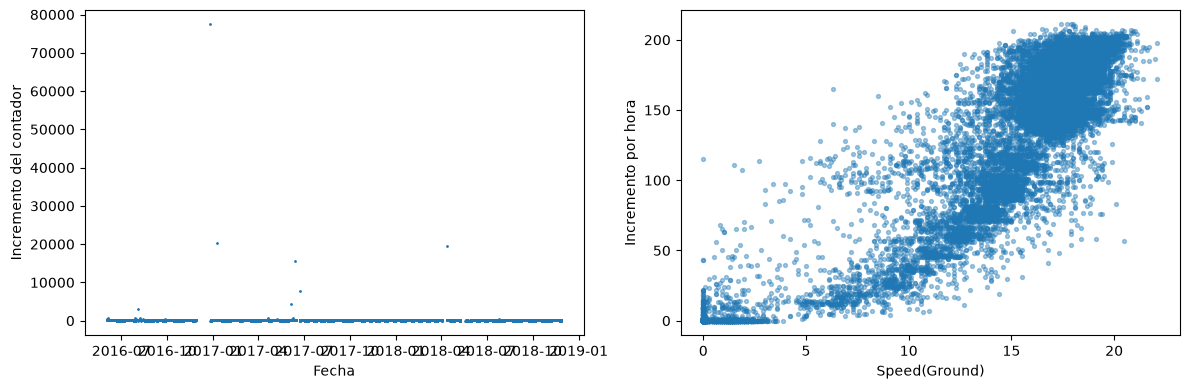

In [3]:
train['delta_contador'] = train.contador.diff()
train['duracion_h'] = train.fecha.diff().dt.total_seconds() / 3600
print('Incrementos negativos:', int((train.delta_contador < 0).sum()))
display(train.loc[train.delta_contador < 0, ['fecha', 'contador', 'delta_contador']])

# Para test usamos la fecha inmediatamente anterior entre los registros disponibles.
# Si existen huecos no registrados, esta duración necesita revisión con el proveedor de los datos.
fechas = pd.DatetimeIndex(pd.concat([train.fecha, test.fecha]).drop_duplicates().sort_values())
posiciones = fechas.get_indexer(test.fecha)
duraciones = np.full(len(test), np.nan)
con_anterior = posiciones > 0
duraciones[con_anterior] = (fechas[posiciones[con_anterior]] - fechas[posiciones[con_anterior] - 1]).total_seconds() / 3600
test['duracion_h'] = duraciones
if test.duracion_h.isna().any():
    raise ValueError('Una fecha de test no tiene registro anterior; falta definir su intervalo')

validos = train.delta_contador.notna() & (train.delta_contador >= 0) & (train.duracion_h > 0)
datos = train.loc[validos].copy()
datos['tasa_contador'] = datos.delta_contador / datos.duracion_h
entradas = predictoras + ['calado', 'antiguedad_calado_h', 'duracion_h']
print('Filas utilizables:', len(datos), '/', len(train))
print('Intervalos de más de una hora:', int((datos.duracion_h > 1).sum()))
display(datos.nlargest(5, 'duracion_h')[['fecha', 'duracion_h', 'delta_contador', 'tasa_contador']])
display(datos[entradas + ['delta_contador', 'tasa_contador']].describe().T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(datos.fecha, datos.delta_contador, '.', markersize=2)
axes[0].set(xlabel='Fecha', ylabel='Incremento del contador')
axes[1].scatter(datos.velocidad, datos.tasa_contador, s=8, alpha=.4)
axes[1].set(xlabel='Speed(Ground)', ylabel='Incremento por hora')
plt.tight_layout()
plt.show()

## 3. Validación temporal

Reservo el último 20 % para evaluación. En el 80 % anterior selecciono el modelo por MAE del incremento, usando ventanas temporales crecientes. El pipeline imputa y escala las numéricas y codifica Beaufort con indicadores.

Como el objetivo es un incremento no negativo, limito a cero las tasas predichas negativas. Aplico la misma regla en validación y al predecir DataTest.

In [4]:
if len(datos) < 40:
    raise ValueError('Muy pocos registros para la validación temporal planteada')
corte = int(.8 * len(datos))
desarrollo, reserva = datos.iloc[:corte], datos.iloc[corte:]
X_des, y_des = desarrollo[entradas], desarrollo.tasa_contador
X_res, y_res = reserva[entradas], reserva.delta_contador
cv = TimeSeriesSplit(n_splits=4, gap=1)

def modelo_base(regresor):
    numericas = [c for c in entradas if c != 'beaufort']
    preparacion = ColumnTransformer([
        ('num', Pipeline([
            ('imputar', SimpleImputer(strategy='median', keep_empty_features=True)),
            ('escalar', StandardScaler())]), numericas),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['beaufort'])])
    return Pipeline([('preparacion', preparacion), ('modelo', regresor)])

def predecir_incremento(modelo, X):
    tasa = np.maximum(modelo.predict(X), 0)
    return tasa * X.duracion_h.to_numpy()

def puntuacion_incremento(modelo, X, tasa):
    observado = tasa * X.duracion_h.to_numpy()
    return -mean_absolute_error(observado, predecir_incremento(modelo, X))

candidatos = {
    'Ridge': (Ridge(), {'modelo__alpha': [.01, 1., 100.]}),
    'Bosque': (RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1),
               {'modelo__min_samples_leaf': [2, 10], 'modelo__max_features': [.7, 1.]}),
    'Gradiente': (HistGradientBoostingRegressor(random_state=42, early_stopping=False),
                  {'modelo__max_leaf_nodes': [7, 15], 'modelo__l2_regularization': [0., 1.]})}
busquedas, filas = {}, []
for nombre, (regresor, grilla) in candidatos.items():
    busqueda = GridSearchCV(modelo_base(regresor), grilla, cv=cv,
        scoring=puntuacion_incremento, n_jobs=1, error_score='raise')
    with threadpool_limits(limits=1):
        busqueda.fit(X_des, y_des)
    busquedas[nombre] = busqueda
    filas.append({'modelo': nombre, 'MAE CV': -busqueda.best_score_, 'parametros': busqueda.best_params_})
comparacion_cv = pd.DataFrame(filas).sort_values('MAE CV')
display(comparacion_cv)
elegido = comparacion_cv.iloc[0].modelo
print('Modelo elegido con validación temporal:', elegido)

,modelo,MAE CV,parametros
2,Gradiente,20.422743,"{'modelo__l2_regularization': 1.0, 'modelo__ma..."
1,Bosque,21.559321,"{'modelo__max_features': 0.7, 'modelo__min_sam..."
0,Ridge,27.015920,{'modelo__alpha': 0.01}


Modelo elegido con validación temporal: Gradiente


## 4. Evaluación interna y predicciones

Comparo con la media de los incrementos de desarrollo. Luego reajusto con todas las tasas válidas y predigo los incrementos de DataTest, conservando su fecha y orden original. DataTest no incluye el contador, así que sus errores no se pueden calcular.

,MAE,RMSE,R2
Media,45.054476,62.516755,-0.057950
Gradiente,8.463339,14.596912,0.942324


Tasas negativas antes de limitar a cero en reserva: 0


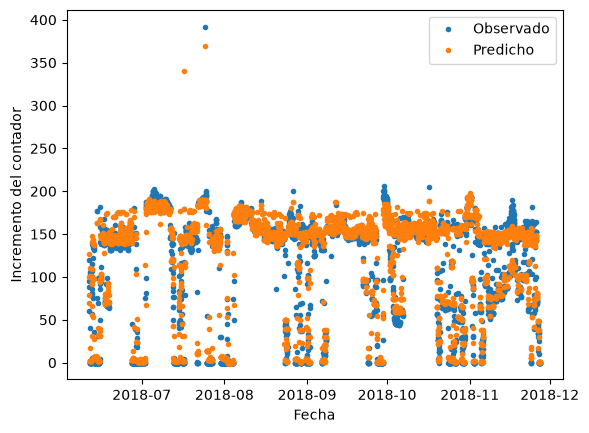

Tasas negativas antes de limitar a cero en DataTest: 18


,fila_original,fecha,delta_contador_predicho
0,0,2018-11-27 10:00:00+00:00,0.0
1,1,2018-11-27 11:00:00+00:00,0.0
2,2,2018-11-27 12:00:00+00:00,0.0
3,3,2018-11-27 13:00:00+00:00,0.0
4,4,2018-11-27 14:00:00+00:00,0.0


Filas exportadas: 4429


In [5]:
def metricas(y, pred):
    return {'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred)), 'R2': r2_score(y, pred)}

referencia = modelo_base(DummyRegressor()).fit(X_des, desarrollo.delta_contador)
modelo = busquedas[elegido].best_estimator_
pred_res = predecir_incremento(modelo, X_res)
display(pd.DataFrame({'Media': metricas(y_res, referencia.predict(X_res)),
                      elegido: metricas(y_res, pred_res)}).T)
print('Tasas negativas antes de limitar a cero en reserva:', int((modelo.predict(X_res) < 0).sum()))
plt.plot(reserva.fecha, y_res, '.', label='Observado')
plt.plot(reserva.fecha, pred_res, '.', label='Predicho')
plt.xlabel('Fecha')
plt.ylabel('Incremento del contador')
plt.legend()
plt.show()

# Reajustamos parámetros; la configuración ya fue elegida sin DataTest.
from sklearn.base import clone
with threadpool_limits(limits=1):
    final = clone(modelo).fit(datos[entradas], datos.tasa_contador)
pred_test = predecir_incremento(final, test[entradas])
print('Tasas negativas antes de limitar a cero en DataTest:', int((final.predict(test[entradas]) < 0).sum()))
assert np.isfinite(pred_test).all() and (pred_test >= 0).all()
salida = test[['fila_original', 'fecha']].copy()
salida['delta_contador_predicho'] = pred_test
salida = salida.sort_values('fila_original')
salida.to_csv('predicciones_DataTest.csv', index=False)
display(salida.head())
print('Filas exportadas:', len(salida))
assert len(salida) == len(test_crudo)

La validación temporal eligió Gradiente, con MAE de 20.42. En la reserva obtiene MAE 8.46, RMSE 14.60 y R² 0.942; la referencia media obtiene MAE 45.05 y RMSE 62.52. Ajustar por hora evita mezclar directamente consumos acumulados durante intervalos muy distintos.

El CSV contiene 4429 incrementos finitos y no negativos. Las tasas negativas se limitaron a cero antes de convertirlas a incrementos. Los intervalos largos siguen siendo menos fiables porque faltan las condiciones intermedias. La reserva sirve como comprobación después de las correcciones; sus resultados anteriores ya se habían revisado.